---
title: 'Mobiles Price Classification'
description: ' '
date: 2023-04-21
categories: [Machine Learning, Classification]
image: images/mobiles.jpg
---

<ol class="breadcrumb">
  <li class="breadcrumb-item"><a href="../../home.qmd">Home</a></li>
  <li class="breadcrumb-item"><a href="../ai/index.qmd">Artificial Intelligence Projects</a></li>
  <li class="breadcrumb-item active">Mobiles Price Classification</li>
</ol>

## Overview

This notebook investigates the use of machine learning models to classify a mobile phone price range using the following dataset.

[<i class="bi bi-download"></i> Download Labeled Dataset (.csv)](data/mobiles.csv){.btn .btn-secondary role="button" download="" target="_blank}

[<i class="bi bi-download"></i> Download Unlabeled Dataset (.csv)](data/mobiles_new.csv){.btn .btn-secondary role="button" download="" target="_blank}

The analysis covers these main steps:

1. Data preprocessing and Exploratory Data Analysis (EDA)
2. Statistical analysis for feature selection
3. Model training
4. Model evaluation

To achieve optimal model performance and understand feature dynamics, the experimental framework is implemented in the model training and evaluation which evaluates two distinct feature representation scenarios across four machine learning algorithms:

1. **Experimental Scenarios:**
   - **Full Feature Set.**
   - **Statistically Selected Feature Set.**
2. **Machine Learning Algorithms:**
   - **K-Nearest Neighbors (KNN):** A distance-based classifier.
   - **Decision Tree:** A single-tree model evaluating rule-based splits.
   - **Random Forest:** An ensemble bagging technique combining multiple decision trees to reduce variance and capture non-linear relationships.
   - **XGBoost:** A gradient boosting algorithm that sequentially corrects residual errors.

Additionally, hyperparameter tuning via **GridSearchCV** is systematically applied across all model configurations to determine optimal model parameters and prevent overfitting.

The primary objective is to perform an end-to-end machine learning process, feature selection, and model choice affect classification performance.

## Install and Import Packages

In [ ]:
%pip install --upgrade -q matplotlib joblib pandas scikit-learn scipy seaborn xgboost

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Load Dataset

In [3]:
df = pd.read_csv('data/mobiles.csv')
df

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,794,1,0.5,1,0,1,2,0.8,106,6,...,1222,1890,668,13,4,19,1,1,0,0
1996,1965,1,2.6,1,0,0,39,0.2,187,4,...,915,1965,2032,11,10,16,1,1,1,2
1997,1911,0,0.9,1,1,1,36,0.7,108,8,...,868,1632,3057,9,1,5,1,1,0,3
1998,1512,0,0.9,0,4,1,46,0.1,145,5,...,336,670,869,18,10,19,1,1,1,0


## Data Preprocessing and EDA

First, let's take a look at the datasets overview.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

Based on the output above, here are some informations about the dataset.
- The dataset has 2000 rows and 21 columns.
- The target variable is 'price_range'.
- Notice that there is no feature with missing values. 
- All features are already in numerical form so that they don't need an encoding for the categorical features.

In [6]:
df['price_range'].value_counts()

price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64

<Axes: xlabel='price_range'>

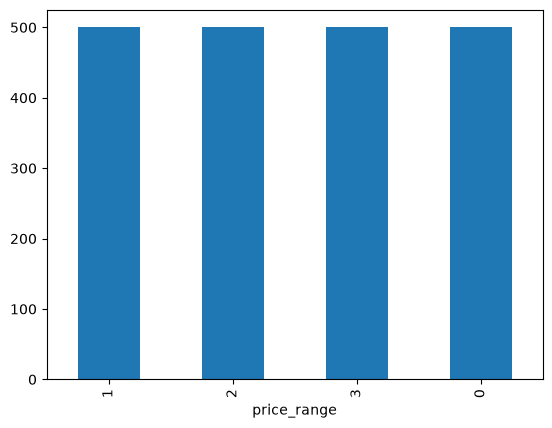

In [4]:
df['price_range'].value_counts().plot(kind='bar')

We can see that the dataset is **balanced** since it has exactly same number of data points for each class in the target variable 'price_range'. 

#### Checking dan Dropping Duplicated Rows

Let's check the duplicated rows in train dataset and drop them if exist.

In [8]:
# check and drop duplicated rows (if exist)
total_duplicates = df.duplicated().sum()
print(f'Total duplicated rows: {total_duplicates}')
if total_duplicates:
    df = df.drop_duplicates()
    print('All duplicated rows has been removed.')
else:
    print('No duplicated rows need to be dropped.')

Total duplicated rows: 0
No duplicated rows need to be dropped.


### Data Visualization and Feature Selection

In [9]:
print('-----Unique Values and Mode in Each Column-----\n\n')
all_columns = df.drop(columns=['price_range']).columns.tolist()
for column in all_columns:
    print(f'Unique Values in {column}:')
    print(df[column].unique().tolist())
    print()
    print(f'Mode: {df[column].mode()[0]}')
    print('='*50)

-----Unique Values and Mode in Each Column-----


Unique Values in battery_power:
[842, 1021, 563, 615, 1821, 1859, 1954, 1445, 509, 769, 1520, 1815, 803, 1866, 775, 838, 595, 1131, 682, 772, 1709, 1949, 1602, 503, 961, 519, 956, 1453, 851, 1579, 1568, 1319, 1310, 644, 725, 589, 1725, 790, 560, 1347, 1646, 1253, 1656, 1195, 1514, 1723, 1054, 578, 596, 1547, 1760, 1654, 1457, 1073, 1936, 823, 987, 1757, 1063, 1484, 799, 1156, 1720, 702, 616, 1358, 1242, 1166, 1448, 1407, 605, 1038, 797, 819, 1114, 1234, 1199, 1103, 1589, 999, 1510, 1008, 1127, 1412, 1496, 1083, 668, 1309, 1724, 1977, 885, 879, 1322, 1137, 1355, 1665, 657, 593, 1883, 1732, 543, 1939, 553, 832, 1661, 1657, 1135, 1775, 783, 617, 867, 1804, 1900, 909, 1084, 1308, 1778, 1701, 825, 1379, 1659, 826, 1564, 1957, 1571, 1414, 1790, 645, 1652, 1213, 1272, 866, 536, 523, 1753, 1218, 1537, 786, 1678, 1814, 1101, 1461, 1216, 506, 843, 742, 1692, 1485, 637, 1224, 1356, 1840, 1481, 1296, 1193, 1441, 517, 748, 1126, 1572, 1569, 1270, 18

##### Train-Test Split

Split the the data into train and test set. Here, we are using 80:20 ratio for the train and test set. 

In [5]:
from sklearn.model_selection import train_test_split

# separate the target variable
target = 'price_range'
y = df[target].values

X_df = df.drop(columns=[target])

# split the data into train and test set
X_train_df, X_test_df, y_train, y_test = train_test_split(X_df, y, test_size=0.2, random_state=42)
print(f'X_train_df shape: {X_train_df.shape}')
print(f'X_test_df shape: {X_test_df.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape: {y_test.shape}')

X_train_df shape: (1600, 20)
X_test_df shape: (400, 20)
y_train shape: (1600,)
y_test shape: (400,)


In [6]:
X_train_df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
968,1923,0,0.5,1,7,0,46,0.5,191,1,10,767,1759,1489,10,9,3,1,1,1
240,633,1,2.2,0,0,1,49,0.1,139,8,1,529,1009,3560,11,1,16,1,1,1
819,1236,0,0.9,1,2,1,57,0.1,188,1,14,517,809,1406,14,12,20,1,0,1
692,781,0,1.1,0,2,0,38,0.4,198,5,7,304,1674,3508,13,8,5,0,0,1
420,1456,1,0.5,1,7,0,7,0.4,105,5,12,823,1104,1587,6,5,20,1,0,1


In [7]:
X_test_df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
1860,1646,0,2.5,0,3,1,25,0.6,200,2,5,211,1608,686,8,6,11,1,1,0
353,1182,0,0.5,0,7,1,8,0.5,138,8,16,275,986,2563,19,17,19,1,0,0
1333,1972,0,2.9,0,9,0,14,0.4,196,7,18,293,952,1316,8,1,8,1,1,0
905,989,1,2.0,0,4,0,17,0.2,166,3,19,256,1394,3892,18,7,19,1,1,0
1289,615,1,0.5,1,7,0,58,0.5,130,5,8,1021,1958,1906,14,5,5,1,0,0


In [8]:
y_train

array([1, 2, 0, ..., 2, 3, 1], shape=(1600,))

In [9]:
y_test

array([0, 2, 1, 3, 1, 1, 2, 0, 3, 1, 0, 0, 2, 3, 3, 2, 3, 3, 1, 0, 0, 2,
       1, 2, 0, 1, 3, 2, 2, 0, 0, 0, 3, 0, 1, 1, 2, 0, 3, 0, 2, 3, 2, 0,
       2, 3, 2, 1, 3, 1, 3, 1, 0, 0, 1, 0, 1, 3, 0, 0, 1, 3, 3, 1, 0, 0,
       3, 3, 1, 2, 2, 2, 0, 1, 2, 0, 1, 3, 2, 2, 3, 2, 1, 0, 1, 3, 1, 3,
       3, 0, 3, 3, 2, 1, 3, 2, 2, 3, 1, 1, 0, 0, 1, 0, 0, 3, 2, 0, 1, 1,
       0, 0, 3, 1, 3, 2, 3, 2, 0, 2, 1, 3, 2, 1, 3, 3, 0, 2, 0, 2, 3, 0,
       2, 2, 0, 3, 1, 0, 0, 2, 2, 1, 3, 2, 0, 0, 0, 1, 1, 2, 3, 1, 1, 0,
       2, 2, 0, 1, 0, 2, 2, 3, 3, 2, 1, 0, 1, 2, 2, 3, 3, 0, 1, 0, 3, 1,
       1, 2, 1, 0, 0, 0, 0, 0, 3, 2, 0, 3, 0, 0, 0, 0, 1, 3, 3, 1, 0, 1,
       1, 1, 1, 2, 2, 3, 3, 3, 1, 2, 0, 0, 0, 2, 1, 1, 3, 1, 0, 2, 1, 1,
       3, 2, 3, 0, 0, 2, 1, 3, 0, 1, 2, 0, 2, 3, 2, 0, 1, 3, 3, 0, 1, 3,
       2, 3, 0, 3, 1, 2, 3, 3, 2, 1, 0, 3, 3, 1, 3, 3, 3, 3, 3, 0, 1, 2,
       2, 2, 3, 0, 2, 3, 2, 2, 2, 1, 0, 2, 0, 3, 3, 1, 3, 1, 0, 3, 1, 2,
       0, 0, 3, 0, 1, 2, 3, 3, 3, 1, 1, 0, 1, 3, 3,

For the next exploratory data analysis, it is conducted exclusively on the Training Set. The Test Set remains completely untouched and unseen, acting as pure out-of-sample data to ensure an unbiased evaluation of the final model. Then, divide the training dataset into 2 parts: numerical features only and categorical features only.

In [10]:
# divide the dataframe into 2 parts: numerical features only and categorical features only
cat_columns = ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi']
num_columns = list(set(X_df.columns) - set(cat_columns))

X_train_cat_df = X_train_df[cat_columns]
X_train_num_df = X_train_df[num_columns]

print(f'X_train_cat_df shape: {X_train_cat_df.shape}')
print(f'X_train_num_df shape: {X_train_num_df.shape}')

X_train_cat_df shape: (1600, 6)
X_train_num_df shape: (1600, 14)


#### Categorical Features

Let's create grouped bar charts to visualize the categorical features.

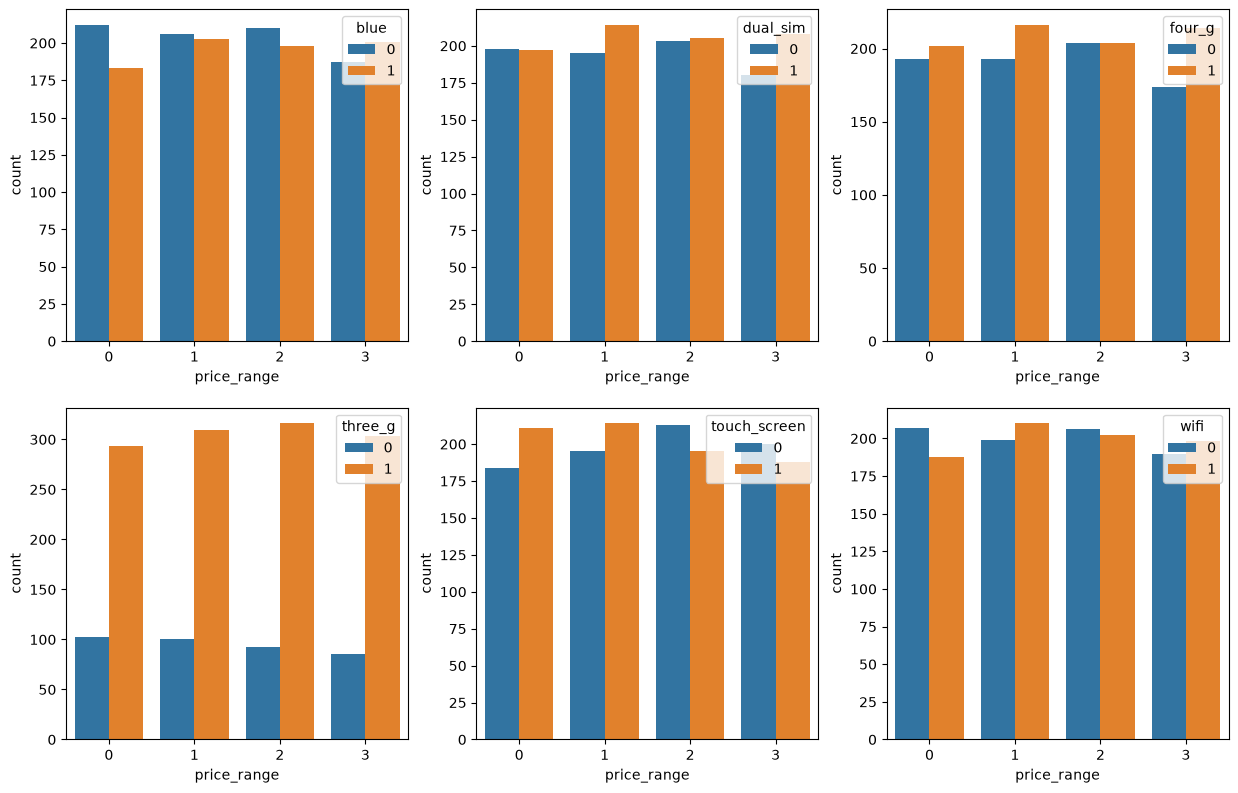

In [11]:
countplot_df = X_train_cat_df.copy()
countplot_df[target] = y_train

n_columns = 3
n_rows = (len(num_columns) + n_columns - 1) // n_columns

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for i, column in enumerate(cat_columns):
    sns.countplot(data=countplot_df, x=target, hue=column, ax=axes[i])

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.show()

This side-by-side bar symmetry demonstrates that the presence or absence of these hardware features occurs with equal probability regardless of the smartphone's price level. The visual lack of skewness or concentration reinforces that these binary features are statistically independent of the target, providing further empirical justification for pruning them during the Chi-Square feature selection process.

To determine which categorical features hold significant predictive power over the categorical target variable (price_range), **Chi-Square Test of Independence** is employed.

The Chi-Square Test of Independence evaluates whether a significant association exists between two categorical variables by comparing the **Observed Frequencies ($O$)** in the sample data against the **Expected Frequencies ($E$)**.

**How Expected Frequencies Measure Independence**

In probability theory, if two events $A$ and $B$ are statistically independent (i.e., having no association), the joint probability of both events occurring simultaneously is the product of their individual probabilities:

$$P(A \cap B) = P(A) \times P(B)$$

In the context of contingency tables, the **Expected Frequency ($E_{i,j}$)** for a specific cell—representing the count we would mathematically expect if the feature and the target class were completely unrelated—is computed as:

$$E_{i,j} = \frac{\text{Row Total}_i \times \text{Column Total}_j}{\text{Grand Total (N)}}$$

**Measuring Association via Deviation**
The Chi-Square statistic quantifies the total normalized deviation between reality ($O$) and the assumption of independence ($E$):

$$\chi^2 = \sum \frac{(O_{i,j} - E_{i,j})^2}{E_{i,j}}$$

- **Small $\chi^2$ value ($p \ge 0.05$):** The observed distribution aligns closely with the expected distribution under independence. This indicates that knowing the categorical feature provides no statistically significant information about the target variable ($\text{price\_range}$). Thus, the feature is identified as noise and candidate for removal.
- **Large $\chi^2$ value ($p < 0.05$):** The observed frequencies diverge significantly from the independence baseline. This confirms a statistically significant association with the target, justifying the retention of the feature for machine learning modeling.

In [ ]:
from scipy.stats import chi2_contingency

chi2_df = X_train_cat_df.copy()
chi2_df[target] = y_train

chi2_results = []

print('----- Running Chi-Square Independence Test -----\n')

for column in cat_columns:
    contingency_table = pd.crosstab(chi2_df[column], chi2_df[target])
    
    chi2_stat, p_val, dof, expected = chi2_contingency(contingency_table)

    chi2_results.append({'Feature': column,
                         'Chi-Square Stat': chi2_stat,
                         'P-Value': p_val})
    
chi2_summary_df = pd.DataFrame(chi2_results).sort_values(by='Chi-Square Stat', ascending=False).reset_index(drop=True)
print('Results:\n')
print(chi2_summary_df)

# select features with p-value < 0.05
selected_cat = chi2_summary_df[chi2_summary_df['P-Value'] < 0.05]['Feature'].tolist()
print(f'\nSelected Categorical Features: {selected_cat}\n')
print(f'Number of Selected Categorical Features: {len(selected_cat)} Out of {len(cat_columns)} Categorical Features.')

----- Running Chi-Square Independence Test -----

Results:

        Feature  Chi-Square Stat   P-Value
0  touch_screen         3.733835  0.291677
1          blue         2.447575  0.484840
2        four_g         2.387007  0.496058
3       three_g         2.100655  0.551780
4      dual_sim         1.476924  0.687606
5          wifi         1.403940  0.704611

Selected Categorical Features: []

Number of Selected Categorical Features: 0 Out of 6 Categorical Features.


A comprehensive evaluation of the binary/categorical features (`blue`, `dual_sim`, `four_g`, `three_g`, `touch_screen`, and `wifi`) indicates that these attributes exert virtually **no meaningful impact** on determining a smartphone's price range.

1. **Visual Evidence:**
   Across the grouped bar charts, any of the four target price ranges ($\text{price\_range} \in \{0, 1, 2, 3\}$) hover uniformly around **25%** for both binary states ($0$ and $1$). The lack of structural deviation or concentration in specific cells visually confirms that these features are distributed at random relative to the price categories.

2. **Statistical Confirmation (Chi-Square Test of Independence):**
   This visual independence is rigorously backed by the Chi-Square test of independence. The calculated $\chi^2$ values for all categorical features are small, yielding $p\text{-values} > 0.05$. Consequently, we fail to reject the null hypothesis ($H_0$), confirming that these binary hardware specifications share no statistically significant association with `price_range`. Retaining them would only introduce irrelevant noise into distance-based estimators like KNN.

#### Numerical Features

Let's also explore which numerical features have a strong relationship with the target variable by creating box plots.

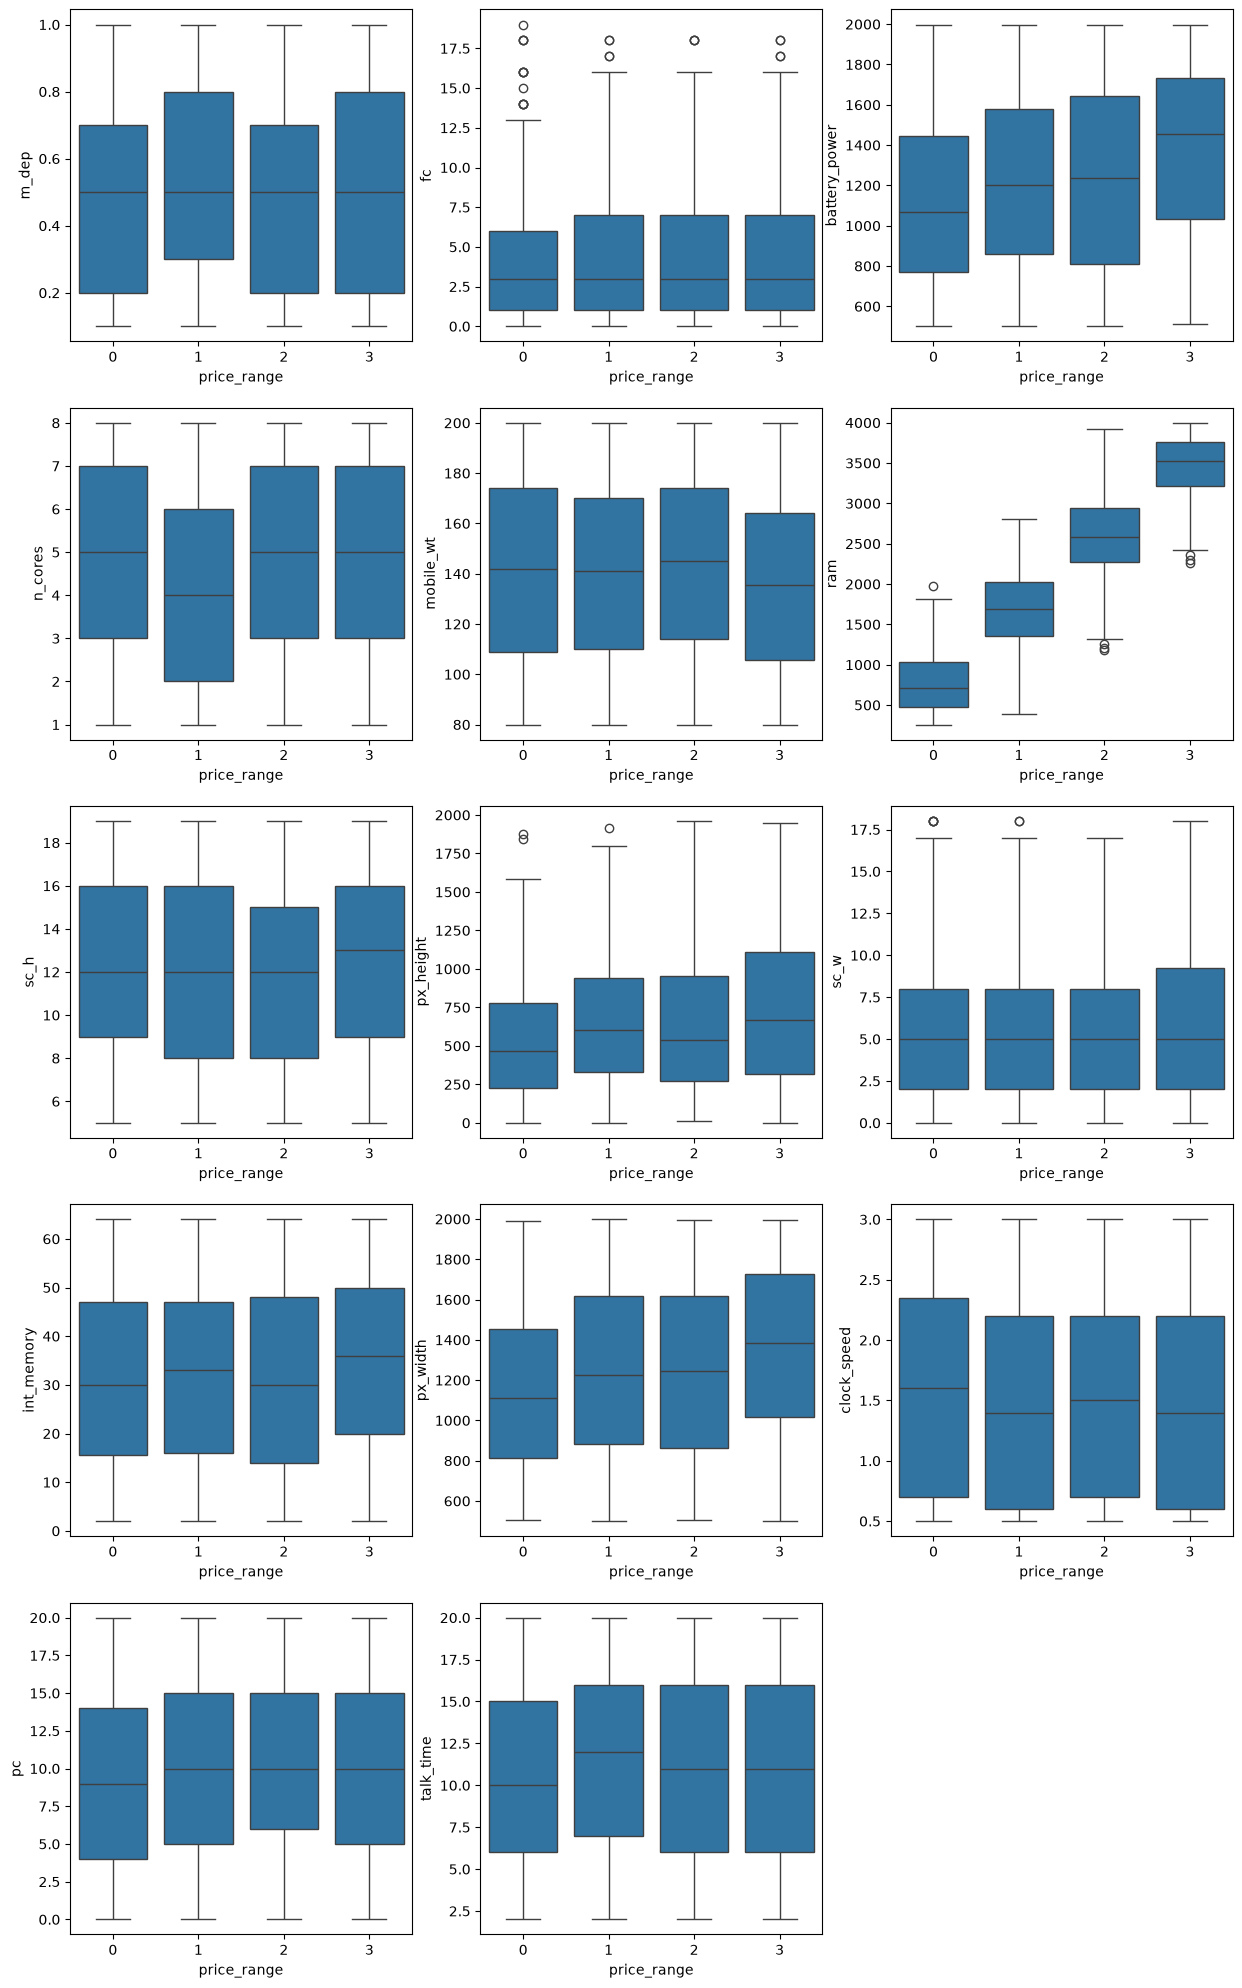

In [13]:
boxplot_df = X_train_num_df.copy()
boxplot_df[target] = y_train

n_columns = 3
n_rows = (len(num_columns) + n_columns - 1) // n_columns

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for i, column in enumerate(num_columns):
    sns.boxplot(boxplot_df, x=target, y=column, ax=axes[i])

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.show()

The boxplot visualization for `ram` demonstrates a distinct, non-overlapping ascending stair-step pattern across the target classes. The median values and interquartile ranges (IQR) for each `price_range` shift dramatically higher with each successive tier:
   - **Price Range 0 (Low):** Characterized by low RAM capacity (predominantly $< 1,000 \text{ MB}$).
   - **Price Range 3 (Very High):** Dominated exclusively by high RAM capacity (approaching $3,000 - 4,000 \text{ MB}$).
   
The absence of overlapping medians confirms that RAM alone provides near-perfect linear separability among the four price classes.

To determine which continuous numerical features hold significant predictive power over the categorical target variable (price_range), an Analysis of Variance (**ANOVA**) F-test is employed. Mathematically, ANOVA evaluates whether the mean of each continuous numerical features differs significantly across all ofthe classes in the target variable. The statistical hypotheses for this evaluation are formulated as follows:

- Null Hypothesis ($H_0$): The mean of a continuous numerical features is identical across all classes in the target variable.

- Alternative Hypothesis ($H_1$): At least one class' mean is significantly different from the others.

A stringent significance threshold of $\alpha = 0.05$ is applied. Categorical features that yield a $p\text{-value} < 0.05$ allow us to rigorously reject the null hypothesis, confirming that the variance between the category means is statistically significant and not due to random chance. These verified features are selected for downstream dummy encoding and modeling, while non-significant features are discarded to keep the model parsimonious.

**How Simple Comparison of Group Means Can Dictate The Relationship between Numerical and Categorical Data**

If we discover that the mean of a numerical feature in price_range 0 is structurally different from price_range 1, price_range 2, and price_range 3, it demonstrates that knowing the value of that numerical feature provides immediate information about the target's class. Mathematically, this implies that the variance between the groups is much larger than the variance within the groups.

In [ ]:
from scipy import stats

anova_df = X_train_num_df.copy()
anova_df[target] = y_train

anova_results = []

print('----- Running ANOVA Test -----\n')

for column in num_columns:

    unique_cats = anova_df[target].unique()
    
    grouped_data = [anova_df[anova_df[target] == cat][column].values for cat in unique_cats]

    f_stat, p_val = stats.f_oneway(*grouped_data)
    
    anova_results.append({
        'Feature': column,
        'F-Statistic': f_stat,
        'P-Value': p_val
    })

# convert to DataFrame and sort by F_Statistics in descending order
anova_summary_df = pd.DataFrame(anova_results).sort_values(by='F-Statistic', ascending=False).reset_index(drop=True)

print('Results:\n')
print(anova_summary_df)

# select features with p-value < 0.05
selected_num = anova_summary_df[anova_summary_df['P-Value'] < 0.05]['Feature'].tolist()
print(f'\nSelected Numerical Features: {selected_num}\n')
print(f'Number of Selected Numerical Features: {len(selected_num)} Out of {len(num_columns)} Numerical Features.')

----- Running ANOVA Test -----

Results:

          Feature  F-Statistic       P-Value
0             ram  2760.069393  0.000000e+00
1   battery_power    23.083657  1.255203e-14
2        px_width    16.183182  2.302349e-10
3       px_height    14.065180  4.736223e-09
4      int_memory     4.981509  1.922441e-03
5       mobile_wt     3.197662  2.262644e-02
6            sc_h     2.072448  1.019529e-01
7         n_cores     1.595945  1.884610e-01
8           m_dep     1.574918  1.935476e-01
9       talk_time     1.500694  2.125445e-01
10             fc     1.061214  3.644836e-01
11    clock_speed     1.037116  3.750794e-01
12           sc_w     0.988743  3.971462e-01
13             pc     0.780857  5.046006e-01

Selected Numerical Features: ['ram', 'battery_power', 'px_width', 'px_height', 'int_memory', 'mobile_wt']

Number of Selected Numerical Features: 6 Out of 14 Numerical Features.


The One-Way ANOVA test yields an exceptionally **massive F-statistic** for `ram` alongside an empirical **$p\text{-value} \approx 0.0$** (far below the standard $\alpha = 0.05$ threshold). This indicates that the variance between price class means for RAM is extraordinarily large compared to the variance within each class, formally establishing `ram` as the single most statistically significant feature in the dataset.

### Numerical Features Standardization

As observed in the plots for numerical features, the numerical features exhibit vastly different scales and measurement ranges. One of the models that will be used here is K-Nearest Neighbor which is highly sensitive to these scale discrepancies because the optimization algorithm might inadvertently penalize or over-allocate weight to features with larger absolute magnitudes. 

To mitigate this, StandardScaler is applied to transform all numerical features to possess a mean of 0 and a standard deviation of 1 ($\mu = 0, \sigma = 1$).

In [15]:
from sklearn.preprocessing import StandardScaler

X_test_num_df = X_test_df[num_columns]

scaler = StandardScaler()
X_train_num = X_train_num_df.values
X_test_num = X_test_num_df.values

X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

X_train_num_scaled_df = pd.DataFrame(data=X_train_num_scaled, columns=num_columns)
X_test_num_scaled_df = pd.DataFrame(data=X_test_num_scaled, columns=num_columns)

print(f'X_train_num_scaled_df shape: {X_train_num_scaled_df.shape}')
print(f'X_test_num_scaled_df shape: {X_test_num_scaled_df.shape}')

X_train_num_scaled_df shape: (1600, 14)
X_test_num_scaled_df shape: (400, 14)


In [16]:
X_train_num_scaled_df.head()

,m_dep,fc,battery_power,n_cores,mobile_wt,ram,sc_h,px_height,sc_w,int_memory,px_width,clock_speed,pc,talk_time
0,-0.008935,0.620111,1.548360,-1.547446,1.425710,-0.580476,-0.528061,0.275712,0.759509,0.754832,1.181997,-1.236230,0.020269,-1.445123
1,-1.403674,-0.993561,-1.379535,1.510316,-0.046246,1.336453,-0.290196,-0.258762,-1.084869,0.919763,-0.556547,0.837112,-1.476497,0.915929
2,-1.403674,-0.532512,-0.010914,-1.547446,1.340790,-0.657302,0.423400,-0.285711,1.451150,1.359577,-1.020159,-0.748385,0.685498,1.642407
3,-0.357620,-0.532512,-1.043621,0.199847,1.623858,1.288322,0.185535,-0.764042,0.528962,0.315017,0.984962,-0.504462,-0.478653,-1.081884
4,-0.357620,0.620111,0.488416,0.199847,-1.008680,-0.489767,-1.479523,0.401470,-0.162680,-1.389265,-0.336332,-1.236230,0.352883,1.642407


In [17]:
X_test_num_scaled_df.head()

,m_dep,fc,battery_power,n_cores,mobile_wt,ram,sc_h,px_height,sc_w,int_memory,px_width,clock_speed,pc,talk_time
0,0.339750,-0.301987,0.919657,-1.110623,1.680472,-1.323738,-1.003792,-0.972891,0.067867,-0.399682,0.831970,1.202995,-0.811268,0.007832
1,-0.008935,0.620111,-0.133477,1.510316,-0.074553,0.413624,1.612728,-0.829167,2.603886,-1.334288,-0.609863,-1.236230,1.018112,1.460787
2,-0.357620,1.081160,1.659574,1.073493,1.567245,-0.740606,-1.003792,-0.788745,-1.084869,-1.004427,-0.688677,1.690840,1.350727,-0.537026
3,-1.054989,-0.071463,-0.571527,-0.673800,0.718039,1.643754,1.374862,-0.871835,0.298414,-0.839496,0.335906,0.593189,1.517034,1.460787
4,-0.008935,0.620111,-1.420389,0.199847,-0.301008,-0.194499,0.423400,0.846117,-0.162680,1.414554,1.643291,-1.236230,-0.312346,-1.081884


In [40]:
# full and unscaled: X_train_df, X_test_df

# full and scaled
X_train_full_scaled_df = pd.concat([X_train_cat_df.reset_index(drop=True), X_train_num_scaled_df.reset_index(drop=True)], axis=1).sort_index(axis=1)
X_test_full_scaled_df = pd.concat([X_test_df[cat_columns].reset_index(drop=True), X_test_num_scaled_df.reset_index(drop=True)], axis=1).sort_index(axis=1)

# selected and unscaled
selected_columns = selected_num + selected_cat
X_train_selected_df = X_train_df[selected_columns].sort_index(axis=1)
X_test_selected_df = X_test_df[selected_columns].sort_index(axis=1)

# selected and scaled
X_train_selected_scaled_df = X_train_full_scaled_df[selected_columns].sort_index(axis=1)
X_test_selected_scaled_df = X_test_full_scaled_df[selected_columns].sort_index(axis=1)

print(f'X_train_full_scaled_df shape: {X_train_full_scaled_df.shape}')
print(f'X_test_full_scaled_df shape: {X_test_full_scaled_df.shape}')
print(f'X_train_selected_df shape: {X_train_selected_df.shape}')
print(f'X_test_selected_df shape: {X_test_selected_df.shape}')
print(f'X_train_selected_scaled_df shape: {X_train_selected_scaled_df.shape}')
print(f'X_test_selected_scaled_df shape: {X_test_selected_scaled_df.shape}')

X_train_full_scaled_df shape: (1600, 20)
X_test_full_scaled_df shape: (400, 20)
X_train_selected_df shape: (1600, 6)
X_test_selected_df shape: (400, 6)
X_train_selected_scaled_df shape: (1600, 6)
X_test_selected_scaled_df shape: (400, 6)


In [41]:
X_train_full_scaled_df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1.548360,0,-1.236230,1,0.620111,0,0.754832,-0.008935,1.425710,-1.547446,0.020269,0.275712,1.181997,-0.580476,-0.528061,0.759509,-1.445123,1,1,1
1,-1.379535,1,0.837112,0,-0.993561,1,0.919763,-1.403674,-0.046246,1.510316,-1.476497,-0.258762,-0.556547,1.336453,-0.290196,-1.084869,0.915929,1,1,1
2,-0.010914,0,-0.748385,1,-0.532512,1,1.359577,-1.403674,1.340790,-1.547446,0.685498,-0.285711,-1.020159,-0.657302,0.423400,1.451150,1.642407,1,0,1
3,-1.043621,0,-0.504462,0,-0.532512,0,0.315017,-0.357620,1.623858,0.199847,-0.478653,-0.764042,0.984962,1.288322,0.185535,0.528962,-1.081884,0,0,1
4,0.488416,1,-1.236230,1,0.620111,0,-1.389265,-0.357620,-1.008680,0.199847,0.352883,0.401470,-0.336332,-0.489767,-1.479523,-0.162680,1.642407,1,0,1


In [42]:
X_train_selected_df.head()

,battery_power,int_memory,mobile_wt,px_height,px_width,ram
968,1923,46,191,767,1759,1489
240,633,49,139,529,1009,3560
819,1236,57,188,517,809,1406
692,781,38,198,304,1674,3508
420,1456,7,105,823,1104,1587


In [43]:
X_train_selected_scaled_df.head()

,battery_power,int_memory,mobile_wt,px_height,px_width,ram
0,1.548360,0.754832,1.425710,0.275712,1.181997,-0.580476
1,-1.379535,0.919763,-0.046246,-0.258762,-0.556547,1.336453
2,-0.010914,1.359577,1.340790,-0.285711,-1.020159,-0.657302
3,-1.043621,0.315017,1.623858,-0.764042,0.984962,1.288322
4,0.488416,-1.389265,-1.008680,0.401470,-0.336332,-0.489767


## Run The Experiment: Train and Evaluate Models Using Hyperparameter Tuning

In [45]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold, GridSearchCV


experiments = [
    # knn experiments
    {
        'name': 'KNN_Full_Features',
        'model': KNeighborsClassifier(),
        'use_selected_features': False,
        'needs_scaling': True,
        'params': {
            'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21],
        }
    },
    {
        'name': 'KNN_Feature_Selection',
        'model': KNeighborsClassifier(),
        'use_selected_features': True,
        'needs_scaling': True,
        'params': {
            'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21],
        }
    },
    
    # decision tree Experiments
    {
        'name': 'DecisionTree_Full_Features',
        'model': DecisionTreeClassifier(random_state=42),
        'use_selected_features': False,
        'needs_scaling': False,
        'params': {
            'criterion': ['gini', 'entropy'],
            'max_depth': [None, 3, 5, 7, 10]
        }
    },
    {
        'name': 'DecisionTree_Feature_Selection',
        'model': DecisionTreeClassifier(random_state=42),
        'use_selected_features': True,
        'needs_scaling': False,
        'params': {
            'criterion': ['gini', 'entropy'],
            'max_depth': [None, 3, 5, 7, 10]
        }
    },

    # random forest experiments
    {
        'name': 'RandomForest_Full_Features',
        'model': RandomForestClassifier(random_state=42),
        'use_selected_features': False,
        'needs_scaling': False,
        'params': {
            'criterion': ['gini', 'entropy'],
            'max_depth': [None, 3, 5, 7, 10],
            'n_estimators': [100, 200, 300, 400, 500]
        }
    },
    {
        'name': 'RandomForest_Feature_Selection',
        'model': RandomForestClassifier(random_state=42),
        'use_selected_features': True,
        'needs_scaling': False,
        'params': {
            'criterion': ['gini', 'entropy'],
            'max_depth': [None, 3, 5, 7, 10],
            'n_estimators': [100, 200, 300, 400, 500]
        }
    },

    # xgboost experiments
    {
        'name': 'XGBoost_Full_Features',
        'model': XGBClassifier(objective='multi:softprob', num_class=4, random_state=42),
        'use_selected_features': False,
        'needs_scaling': False,
        'params': {
            'n_estimators': [50, 100, 200],
            'learning_rate': [0.01, 0.05, 0.1, 0.2],
            'max_depth': [3, 5, 7]
        }
    },
    {
        'name': 'XGBoost_Feature_Selection',
        'model': XGBClassifier(objective='multi:softprob', num_class=4, random_state=42),
        'use_selected_features': True,
        'needs_scaling': False,
        'params': {
            'n_estimators': [50, 100, 200],
            'learning_rate': [0.01, 0.05, 0.1, 0.2],
            'max_depth': [3, 5, 7]
        }
    }
]

results_list = []

for exp in experiments:
    print(f'Running Experiment: {exp['name']}')

    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    grid_cv = GridSearchCV(
        estimator=exp['model'],
        param_grid=exp['params'],
        cv=kf,
        scoring='accuracy',
        n_jobs=-1
    )

    if exp['use_selected_features']:
        if exp['needs_scaling']:
            X_train =  X_train_selected_scaled_df.values
            X_test = X_test_selected_scaled_df.values
        else:
            X_train =  X_train_selected_df.values
            X_test = X_test_selected_df.values
    else:
        if exp['needs_scaling']:
            X_train = X_train_full_scaled_df.values
            X_test = X_test_full_scaled_df.values
        else:
            X_train = X_train_df.values
            X_test = X_test_df.values
            
    grid_cv.fit(X_train, y_train)
    best_model = grid_cv.best_estimator_
    test_accuracy = best_model.score(X_test, y_test)
    
    results_list.append({
        'Experiment': exp['name'],
        'Best Parameters': grid_cv.best_params_,
        'Best CV Score': grid_cv.best_score_,
        'Test Accuracy': test_accuracy
    })

# Convert summary into DataFrame for notebook presentation
results_df = pd.DataFrame(results_list)
results_df

Running Experiment: KNN_Full_Features
Running Experiment: KNN_Feature_Selection
Running Experiment: DecisionTree_Full_Features
Running Experiment: DecisionTree_Feature_Selection
Running Experiment: RandomForest_Full_Features
Running Experiment: RandomForest_Feature_Selection
Running Experiment: XGBoost_Full_Features
Running Experiment: XGBoost_Feature_Selection


,Experiment,Best Parameters,Best CV Score,Test Accuracy
0,KNN_Full_Features,{'n_neighbors': 21},0.646875,0.6850
1,KNN_Feature_Selection,{'n_neighbors': 19},0.803750,0.8175
2,DecisionTree_Full_Features,"{'criterion': 'entropy', 'max_depth': None}",0.855625,0.8500
3,DecisionTree_Feature_Selection,"{'criterion': 'entropy', 'max_depth': None}",0.868750,0.8475
4,RandomForest_Full_Features,"{'criterion': 'entropy', 'max_depth': None, 'n...",0.889375,0.9000
5,RandomForest_Feature_Selection,"{'criterion': 'gini', 'max_depth': None, 'n_es...",0.913125,0.9275
6,XGBoost_Full_Features,"{'learning_rate': 0.2, 'max_depth': 3, 'n_esti...",0.915000,0.9175
7,XGBoost_Feature_Selection,"{'learning_rate': 0.2, 'max_depth': 3, 'n_esti...",0.921875,0.9125


The empirical results from the 8 experimental configurations provide critical insights into algorithmic behavior and the impact of statistical feature selection on high-dimensional tabular data.

Key Findings & Insights:

1. **The Dramatic Impact of Feature Selection on KNN:**
   - **KNN_Full_Features:** Achieved the lowest performance ($\text{CV: } 64.69\%, \text{ Test: } 68.50\%$). The presence of 20 baseline features severely degraded distance-based metrics due to the curse of dimensionality and noisy categorical attributes.
   - **KNN_Feature_Selection:** Performance jumped significantly ($\text{CV: } 80.38\%, \text{ Test: } 81.75\%$), yielding a **+13.25% improvement in Test Accuracy**. Pruning non-informative variables directly refined the Euclidean distance space.

2. **Resilience of Tree-Based Models:**
   - Single Decision Trees (`DecisionTree`) exhibited stable performance ($\sim 84.75\% - 85.00\%$ Test Accuracy) across both feature sets, proving their native ability to prioritize splits based on Information Gain/Entropy (`criterion='entropy'`).

3. **Dominance of Ensemble Methods (Random Forest & XGBoost):**
   - Ensemble frameworks consistently outperformed single estimators, crossing the $90\%$ accuracy threshold.
   - **Random Forest with Feature Selection** achieved the **highest overall test accuracy of $92.75\%$** ($\text{CV: } 91.31\%$), demonstrating that eliminating low-variance noise features allows bagging ensembles to build higher-quality decision boundaries.
   - **XGBoost** maintained exceptionally tight convergence between CV score and Test Accuracy ($\sim 91.25\% - 92.18\%$), highlighting the robustness of gradient boosting against variance.

When evaluating the top-performing models, a classic trade-off between **Peak Test Accuracy** and **Generalization Stability** emerges:

- **`XGBoost_Full_Features`** demonstrates superior variance control, achieving a remarkably narrow generalization gap of **$0.25\%$** ($\text{CV: } 91.50\% \text{ vs Test: } 91.75\%$). This confirms that gradient boosting seamlessly manages baseline noise across data splits.
- **`RandomForest_Feature_Selection`**, however, delivers the **highest absolute classification accuracy on unseen data ($92.75\%$)** while maintaining a healthy, non-overfitting gap of **$1.44\%$**. 

**Conclusion:** 
`RandomForest_Feature_Selection` is recommended as the primary candidate due to its superior predictive capability ($+1.00\%$ accuracy over XGBoost) and lower feature complexity (adhering to Occam's Razor by discarding non-informative features). Nonetheless, `XGBoost_Full_Features` stands as a highly robust alternative for environments prioritizing strict cross-split stability.

In [57]:
best_model_id = 5
best_model_name = results_df['Experiment'].iloc[best_model_id]
best_params = results_df['Best Parameters'].iloc[best_model_id]

print(f'Best Model: {best_model_name}')
print(f'Best Parameters: {best_params}')

model = experiments[best_model_id]['model'].set_params(**best_params)

exp = experiments[best_model_id]
if exp['use_selected_features']:
    if exp['needs_scaling']:
        X_train =  X_train_selected_scaled_df.values
        X_test = X_test_selected_scaled_df.values
    else:
        X_train =  X_train_selected_df.values
        X_test = X_test_selected_df.values
else:
    if exp['needs_scaling']:
        X_train = X_train_full_scaled_df.values
        X_test = X_test_full_scaled_df.values
    else:
        X_train = X_train_df.values
        X_test = X_test_df.values

model.fit(X_train, y_train)

Best Model: RandomForest_Feature_Selection
Best Parameters: {'criterion': 'gini', 'max_depth': None, 'n_estimators': 200}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [61]:
y_pred = model.predict(X_test)
y_pred

array([0, 2, 1, 3, 1, 1, 2, 0, 3, 1, 0, 1, 2, 3, 2, 2, 3, 3, 1, 0, 0, 1,
       1, 2, 0, 1, 3, 2, 2, 0, 0, 0, 3, 0, 1, 1, 2, 0, 3, 0, 2, 3, 2, 0,
       3, 2, 1, 1, 3, 1, 3, 1, 0, 0, 1, 1, 1, 3, 0, 0, 1, 3, 3, 1, 0, 0,
       3, 3, 1, 2, 2, 2, 0, 1, 2, 0, 0, 3, 2, 2, 3, 2, 1, 0, 1, 3, 1, 3,
       3, 0, 3, 3, 2, 1, 3, 2, 2, 3, 1, 1, 0, 0, 1, 0, 0, 3, 2, 0, 1, 1,
       0, 0, 3, 1, 2, 2, 3, 3, 0, 2, 1, 3, 2, 1, 3, 3, 0, 3, 0, 2, 3, 0,
       2, 2, 0, 3, 1, 0, 0, 2, 3, 1, 2, 2, 0, 0, 0, 1, 1, 2, 3, 1, 1, 0,
       2, 2, 0, 1, 0, 1, 2, 3, 3, 2, 1, 0, 1, 2, 2, 3, 3, 1, 1, 0, 3, 1,
       1, 2, 1, 0, 0, 0, 0, 0, 3, 2, 0, 3, 0, 0, 0, 0, 1, 3, 3, 1, 0, 1,
       1, 1, 1, 2, 2, 2, 3, 3, 1, 2, 0, 0, 0, 2, 1, 1, 3, 1, 0, 2, 1, 1,
       3, 2, 3, 0, 0, 2, 1, 2, 0, 1, 2, 0, 2, 3, 2, 1, 1, 3, 3, 0, 1, 3,
       3, 3, 0, 3, 1, 2, 3, 3, 2, 1, 1, 3, 3, 1, 3, 3, 3, 3, 3, 0, 1, 2,
       2, 1, 2, 0, 2, 3, 2, 2, 2, 1, 0, 2, 0, 3, 3, 1, 3, 1, 0, 3, 1, 2,
       0, 0, 3, 0, 1, 2, 3, 3, 3, 1, 1, 0, 1, 3, 3,

--- Classification Report ---
Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.95      0.97       105
           1       0.89      0.98      0.93        91
           2       0.89      0.86      0.87        92
           3       0.94      0.92      0.93       112

    accuracy                           0.93       400
   macro avg       0.93      0.93      0.93       400
weighted avg       0.93      0.93      0.93       400

--- Confusion Matrix ---


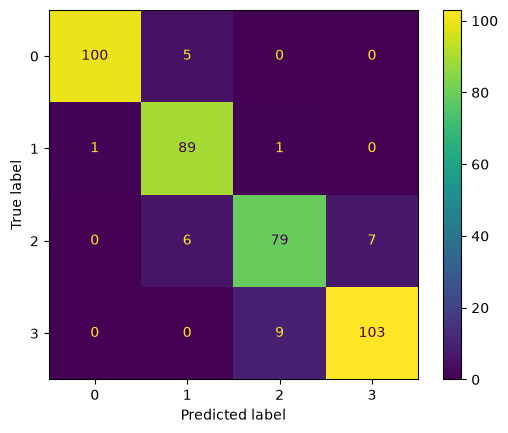

In [64]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("--- Classification Report ---")
report = classification_report(y_test, y_pred)
print('Classification Report:\n')
print(report)

print("--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

## Save Best Model

In [65]:
import joblib

best_model_name = best_model_name.replace(' ', '_').lower()
joblib.dump(model, f'model/mobiles_{best_model_name}.pkl')

['model/mobiles_randomforest_feature_selection.pkl']

### Also Save The Selected Features

In [70]:
with open('model/mobiles_selected_features.txt', mode='w', encoding='utf-8') as f:
    for feature in selected_columns:
        f.write(f'{feature}\n')

# Use The Model to Predict Mobiles Price Range for The New Data

In [54]:
df_new = pd.read_csv('data/mobiles_new.csv')
df_new

,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,...,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1,1043,1,1.8,1,14,0,5,0.1,193,...,16,226,1412,3476,12,7,2,0,1,0
1,2,841,1,0.5,1,4,1,61,0.8,191,...,12,746,857,3895,6,0,7,1,0,0
2,3,1807,1,2.8,0,1,0,27,0.9,186,...,4,1270,1366,2396,17,10,10,0,1,1
3,4,1546,0,0.5,1,18,1,25,0.5,96,...,20,295,1752,3893,10,0,7,1,1,0
4,5,1434,0,1.4,0,11,1,49,0.5,108,...,18,749,810,1773,15,8,7,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,1700,1,1.9,0,0,1,54,0.5,170,...,17,644,913,2121,14,8,15,1,1,0
996,997,609,0,1.8,1,0,0,13,0.9,186,...,2,1152,1632,1933,8,1,19,0,1,1
997,998,1185,0,1.4,0,1,1,8,0.5,80,...,12,477,825,1223,5,0,14,1,0,0
998,999,1533,1,0.5,1,0,0,50,0.4,171,...,12,38,832,2509,15,11,6,0,1,0


In [66]:
df_new.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             1000 non-null   int64  
 1   battery_power  1000 non-null   int64  
 2   blue           1000 non-null   int64  
 3   clock_speed    1000 non-null   float64
 4   dual_sim       1000 non-null   int64  
 5   fc             1000 non-null   int64  
 6   four_g         1000 non-null   int64  
 7   int_memory     1000 non-null   int64  
 8   m_dep          1000 non-null   float64
 9   mobile_wt      1000 non-null   int64  
 10  n_cores        1000 non-null   int64  
 11  pc             1000 non-null   int64  
 12  px_height      1000 non-null   int64  
 13  px_width       1000 non-null   int64  
 14  ram            1000 non-null   int64  
 15  sc_h           1000 non-null   int64  
 16  sc_w           1000 non-null   int64  
 17  talk_time      1000 non-null   int64  
 18  three_g        1000 

In [ ]:
# drop column id

df_new = df_new.drop(columns=['id'])

In [ ]:
# load selected features from the saved txt file
selected_features = []
with open('model/mobiles_selected_features.txt', mode='r', encoding='utf-8') as f:
    for line in f:
        selected_features.append(line.strip())

# filter only selected features and sort the columns in the same order as the training data
df_new = df_new[selected_features].sort_index(axis=1)
df_new

,battery_power,int_memory,mobile_wt,px_height,px_width,ram
0,1043,5,193,226,1412,3476
1,841,61,191,746,857,3895
2,1807,27,186,1270,1366,2396
3,1546,25,96,295,1752,3893
4,1434,49,108,749,810,1773
...,...,...,...,...,...,...
995,1700,54,170,644,913,2121
996,609,13,186,1152,1632,1933
997,1185,8,80,477,825,1223
998,1533,50,171,38,832,2509


In [72]:
X_new = df_new.values

# load saved model
model = joblib.load('model/mobiles_randomforest_feature_selection.pkl')

# predict the price range for new data
y_new_predict = model.predict(X_new)
y_new_predict

array([3, 3, 2, 3, 1, 3, 3, 1, 3, 0, 3, 3, 0, 0, 2, 0, 2, 1, 3, 2, 1, 3,
       1, 1, 3, 0, 2, 0, 2, 0, 2, 0, 3, 0, 0, 1, 3, 1, 2, 1, 1, 2, 0, 0,
       0, 1, 0, 3, 1, 2, 1, 0, 3, 0, 3, 1, 3, 1, 1, 3, 3, 2, 0, 2, 1, 1,
       1, 3, 1, 2, 1, 2, 2, 3, 3, 0, 2, 0, 2, 3, 0, 3, 3, 0, 3, 0, 3, 1,
       3, 0, 1, 2, 2, 0, 2, 1, 0, 2, 1, 2, 1, 0, 0, 3, 1, 2, 0, 1, 2, 3,
       3, 2, 1, 3, 3, 3, 3, 2, 3, 0, 0, 3, 2, 1, 2, 0, 3, 2, 3, 1, 0, 2,
       1, 1, 3, 1, 1, 0, 3, 2, 1, 3, 1, 2, 2, 3, 3, 2, 2, 3, 2, 3, 0, 0,
       3, 2, 3, 3, 3, 3, 2, 2, 3, 3, 3, 3, 1, 0, 3, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 2, 1, 0, 0, 1, 1, 2, 2, 1, 0, 0, 0, 1, 0, 3, 2, 0, 2, 2,
       2, 3, 1, 2, 3, 2, 3, 2, 2, 1, 0, 0, 1, 2, 0, 2, 3, 3, 0, 2, 0, 3,
       2, 3, 3, 1, 0, 1, 0, 3, 0, 1, 0, 2, 2, 1, 2, 0, 3, 0, 3, 1, 2, 0,
       0, 2, 1, 3, 3, 3, 1, 1, 3, 0, 0, 2, 3, 3, 1, 3, 1, 1, 3, 2, 1, 2,
       3, 3, 3, 1, 0, 1, 2, 3, 2, 1, 3, 2, 0, 3, 0, 1, 2, 0, 0, 3, 2, 3,
       3, 2, 1, 3, 3, 2, 3, 2, 2, 1, 2, 0, 2, 3, 1,

In [73]:
df_new['predicted_price_range'] = y_new_predict
df_new

,battery_power,int_memory,mobile_wt,px_height,px_width,ram,predicted_price_range
0,1043,5,193,226,1412,3476,3
1,841,61,191,746,857,3895,3
2,1807,27,186,1270,1366,2396,2
3,1546,25,96,295,1752,3893,3
4,1434,49,108,749,810,1773,1
...,...,...,...,...,...,...,...
995,1700,54,170,644,913,2121,2
996,609,13,186,1152,1632,1933,1
997,1185,8,80,477,825,1223,0
998,1533,50,171,38,832,2509,2


In [74]:
# save results to a new csv file
df_new.to_csv('data/mobiles_new_predicted.csv', index=False)